# Rubin Scheduler: simulazione di un anno e catalogo RA-Dec

Questo notebook usa `rubin_scheduler` per:

1. creare il baseline scheduler;
2. simulare 365.25 giorni di osservazioni;
3. salvare il database della simulazione;
4. estrarre tutte le visite;
5. convertire l'output in un catalogo Pandas;
6. esportare RA, Dec e metadati in CSV e Parquet.

> Prima di eseguire il notebook assicurati di aver installato il software ufficiale:
>
> ```bash
> git clone https://github.com/lsst/rubin_scheduler.git
> cd rubin_scheduler
> pip install -e .
> scheduler_download_data
> pip install pandas astropy pyarrow matplotlib
> ```


In [17]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from astropy.time import Time


## Configurazione della simulazione


In [18]:
# Durata della simulazione
SURVEY_LENGTH_DAYS = 365.25   # un anno

# Risoluzione HEALPix dello scheduler
NSIDE = 32

# MJD iniziale
SURVEY_START_MJD = 61284.0   # 1 settembre 2026

# Directory di output
OUTPUT_DIR = Path("../outputs/rubin_one_year_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SQLITE_FILENAME = "rubin_one_year.db"
CSV_FILENAME = "rubin_visits_ra_dec.csv"
PARQUET_FILENAME = "rubin_visits_ra_dec.parquet"

print("Output directory:", OUTPUT_DIR.resolve())
print("Survey length:", SURVEY_LENGTH_DAYS, "days")
print("Survey start MJD:", SURVEY_START_MJD)
print("NSIDE:", NSIDE)


Output directory: /sdf/home/a/ataranto/straylight/rubin_one_year_output
Survey length: 3.0 days
Survey start MJD: 60979.0
NSIDE: 32


## Import delle librerie ufficiali Rubin


In [19]:
try:
    from rubin_scheduler.scheduler.example import (
        generate_baseline_coresched,
        run_sched,
    )

    import rubin_scheduler

    print("rubin_scheduler importato correttamente")
    print("Version:", getattr(rubin_scheduler, "__version__", "unknown"))

except ImportError as e:
    raise ImportError(
        "rubin_scheduler non trovato. "
        "Installa il repository ufficiale e riesegui il notebook."
    ) from e


rubin_scheduler importato correttamente
Version: 4.5.1.dev3+gc6ace0d73


## Creazione del baseline scheduler

Questa cella costruisce la configurazione baseline fornita dalla versione
installata di `rubin_scheduler`.


In [20]:
import os

# The `!export` command in an earlier notebook cell does not persist.
# Point rubin_scheduler to the downloaded data directory explicitly.
rubin_data_dir = Path.home() / "rubin_sim_data"
os.environ["RUBIN_SIM_DATA_DIR"] = str(rubin_data_dir)

dust_map = (
    rubin_data_dir
    / "scheduler"
    / "dust_maps"
    / f"dust_nside_{NSIDE}.npz"
)

if not dust_map.exists():
    raise FileNotFoundError(
        f"Required Rubin Scheduler data file was not found:\n{dust_map}\n\n"
        "Download the scheduler data with:\n"
        "scheduler_download_data"
    )

scheduler = generate_baseline_coresched(
    nside=NSIDE,
    survey_start_mjd=SURVEY_START_MJD,
)

print("Baseline scheduler creato.")


fatal: not a git repository (or any parent up to mount point /sdf)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).
cat: /sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/lib/python3.13/site-packages/rubin_scheduler/../.git/refs/heads/main: No such file or directory


/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/lib/python3.13/site-packages/rubin_scheduler/scheduler/basis_functions/basis_functions.py:1372: FutureWarning: AvoidDirectWind deprecated, use MaskDirectWindBasisFunction and WindPressureBasisFunction.
  warnings.warn(message, FutureWarning)
/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/lib/python3.13/site-packages/rubin_scheduler/scheduler/basis_functions/basis_functions.py:1372: FutureWarning: AvoidDirectWind deprecated, use MaskDirectWindBasisFunction and WindPressureBasisFunction.
  warnings.warn(message, FutureWarning)
/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/lib/python3.13/site-packages/rubin_scheduler/scheduler/basis_functions/basis_functions.py:1372: FutureWarning: AvoidDirectWind deprecated, use MaskDirectWindBasisFunction and WindPressureBasisFunction.
  warnings.warn(message, FutureWarning)
/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/lib/python3.13/site-packages/rubin_scheduler/scheduler/basis_functions

Baseline scheduler creato.
Baseline scheduler creato.


## Esecuzione della simulazione annuale

Questa è la cella computazionalmente più costosa.

Per un primo test puoi cambiare temporaneamente:

```python
SURVEY_LENGTH_DAYS = 1.0
```

e verificare che tutto funzioni prima di lanciare l'intero anno.


In [21]:
sqlite_path = OUTPUT_DIR / SQLITE_FILENAME

observatory, scheduler, observations = run_sched(
    scheduler,
    survey_length=SURVEY_LENGTH_DAYS,
    nside=NSIDE,
    survey_start_mjd=SURVEY_START_MJD,
    filename=str(sqlite_path),
    verbose=True,
)

print()
print("Simulazione completata")
print("Numero totale di visite:", len(observations))
print("Database:", sqlite_path.resolve())


progress = 1.40%

/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/lib/python3.13/site-packages/rubin_scheduler/utils/healpy_utils.py:373: RuntimeWarning: All-NaN slice encountered
  indx = np.where(in_map[current_neighbors] == np.nanmax(in_map[current_neighbors]))[0]
/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/lib/python3.13/site-packages/rubin_scheduler/utils/healpy_utils.py:376: UserWarning: Can not connect to any more pixels.
  warnings.warn("Can not connect to any more pixels.")


progress = 44.70%

/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/lib/python3.13/site-packages/rubin_scheduler/skybrightness_pre/sky_model_pre.py:406: UserWarning: Requested MJD between sunrise and sunset, returning closest maps
  warnings.warn("Requested MJD between sunrise and sunset, returning closest maps")


progress = 366.90%Skipped 0 observations
Flushed 0 observations from queue for being stale
Completed 1963 observations
ran in 1 min = 0.0 hours

Simulazione completata
Numero totale di visite: 1963
Database: /sdf/home/a/ataranto/straylight/rubin_one_year_output/rubin_one_year.db


## Ispezione della struttura dell'output


In [22]:
print("Campi disponibili nell'array observations:")
print()

for name in observations.dtype.names:
    print("-", name)


Campi disponibili nell'array observations:

- ID
- RA
- dec
- mjd
- flush_by_mjd
- exptime
- band
- filter
- rotSkyPos
- rotSkyPos_desired
- nexp
- airmass
- FWHM_500
- FWHMeff
- FWHM_geometric
- skybrightness
- night
- slewtime
- visittime
- slewdist
- fivesigmadepth
- alt
- az
- pa
- pseudo_pa
- clouds
- moonAlt
- sunAlt
- scheduler_note
- target_name
- target_id
- lmst
- rotTelPos
- rotTelPos_backup
- moonAz
- sunAz
- sunRA
- sunDec
- moonRA
- moonDec
- moonDist
- solarElong
- moonPhase
- cummTelAz
- observation_reason
- science_program
- cloud_extinction
- note


## Conversione dell'output in Pandas DataFrame


In [23]:
df = pd.DataFrame.from_records(observations)

print("Dimensioni del catalogo:")
print(df.shape)

display(df.head())


Dimensioni del catalogo:
(1963, 48)


,ID,RA,dec,mjd,flush_by_mjd,exptime,band,filter,rotSkyPos,rotSkyPos_desired,...,moonRA,moonDec,moonDist,solarElong,moonPhase,cummTelAz,observation_reason,science_program,cloud_extinction,note
0,0,5.762092,-0.895463,60979.001788,60979.04367,30.0,i,i,5.314275,0.0,...,5.692475,-0.270329,0.627624,1.638722,58.741454,3.100884,pairs_iz_15.0,BLOCK-407,0.0,"pair_15, iz, a"
1,1,5.700894,-0.926719,60979.002212,60979.04367,30.0,i,i,5.454463,0.0,...,5.692528,-0.270288,0.656464,1.591144,58.743198,3.197137,pairs_iz_15.0,BLOCK-407,0.0,"pair_15, iz, a"
2,2,5.783368,-0.949413,60979.002640,60979.04367,30.0,i,i,5.276322,0.0,...,5.692582,-0.270246,0.682837,1.623983,58.744962,3.073504,pairs_iz_15.0,BLOCK-407,0.0,"pair_15, iz, a"
3,3,5.718525,-0.981017,60979.003062,60979.04367,30.0,i,i,5.410284,0.0,...,5.692635,-0.270206,0.711086,1.576586,58.746701,3.159705,pairs_iz_15.0,BLOCK-407,0.0,"pair_15, iz, a"
4,4,5.647039,-1.010508,60979.003483,60979.04367,30.0,i,i,5.540344,0.0,...,5.692688,-0.270165,0.741134,1.528962,58.748433,3.234967,pairs_iz_15.0,BLOCK-407,0.0,"pair_15, iz, a"


## Conversione del tempo MJD in datetime UTC


In [24]:
if "mjd" not in df.columns:
    raise RuntimeError("La colonna 'mjd' non è presente nell'output.")

times = Time(
    df["mjd"].values,
    format="mjd",
    scale="utc",
)

df["datetime_utc"] = pd.to_datetime(times.to_datetime())
df["date_utc"] = df["datetime_utc"].dt.date
df["year"] = df["datetime_utc"].dt.year
df["month"] = df["datetime_utc"].dt.month
df["day"] = df["datetime_utc"].dt.day
df["hour_utc"] = df["datetime_utc"].dt.hour

display(df[["mjd", "datetime_utc"]].head())


,mjd,datetime_utc
0,60979.001788,2025-10-31 00:02:34.445061
1,60979.002212,2025-10-31 00:03:11.073784
2,60979.002640,2025-10-31 00:03:48.094707
3,60979.003062,2025-10-31 00:04:24.581106
4,60979.003483,2025-10-31 00:05:00.922683


## Identificazione delle colonne RA e Dec

Lo script cerca automaticamente i nomi più comuni utilizzati nelle diverse
versioni del software.


In [25]:
possible_ra_names = [
    "RA",
    "ra",
    "fieldRA",
]

possible_dec_names = [
    "dec",
    "Dec",
    "DEC",
    "fieldDec",
]

ra_column = next(
    (name for name in possible_ra_names if name in df.columns),
    None,
)

dec_column = next(
    (name for name in possible_dec_names if name in df.columns),
    None,
)

print("RA column:", ra_column)
print("Dec column:", dec_column)

if ra_column is None or dec_column is None:
    raise RuntimeError(
        "Impossibile identificare automaticamente RA e Dec. "
        "Controlla i campi stampati sopra."
    )


RA column: RA
Dec column: dec


## Creazione del catalogo RA-Dec

Le coordinate interne dello scheduler sono normalmente in radianti.

Qui manteniamo sia la versione originale in radianti sia la conversione in gradi:

- `ra_rad`
- `dec_rad`
- `ra_deg`
- `dec_deg`


In [26]:
catalog = df.copy()

catalog["ra_rad"] = catalog[ra_column]
catalog["dec_rad"] = catalog[dec_column]

catalog["ra_deg"] = np.degrees(catalog["ra_rad"]) % 360.0
catalog["dec_deg"] = np.degrees(catalog["dec_rad"])

print("Catalogo RA-Dec creato.")

display(
    catalog[
        [
            "mjd",
            "datetime_utc",
            "ra_rad",
            "dec_rad",
            "ra_deg",
            "dec_deg",
        ]
    ].head()
)


Catalogo RA-Dec creato.


,mjd,datetime_utc,ra_rad,dec_rad,ra_deg,dec_deg
0,60979.001788,2025-10-31 00:02:34.445061,5.762092,-0.895463,330.143581,-51.306276
1,60979.002212,2025-10-31 00:03:11.073784,5.700894,-0.926719,326.637170,-53.097065
2,60979.002640,2025-10-31 00:03:48.094707,5.783368,-0.949413,331.362560,-54.397368
3,60979.003062,2025-10-31 00:04:24.581106,5.718525,-0.981017,327.647347,-56.208110
4,60979.003483,2025-10-31 00:05:00.922683,5.647039,-1.010508,323.551492,-57.897857


## Selezione delle colonne principali


In [27]:
preferred_columns = [
    "mjd",
    "datetime_utc",
    "date_utc",
    "year",
    "month",
    "day",
    "hour_utc",
    "ra_rad",
    "dec_rad",
    "ra_deg",
    "dec_deg",
    "band",
    "filter",
    "alt",
    "az",
    "airmass",
    "rotSkyPos",
    "rotTelPos",
    "exptime",
    "scheduler_note",
]

available_columns = [
    col for col in preferred_columns
    if col in catalog.columns
]

ra_dec_catalog = catalog[available_columns].copy()

print("Colonne esportate:")
print(ra_dec_catalog.columns.tolist())

display(ra_dec_catalog.head())


Colonne esportate:
['mjd', 'datetime_utc', 'date_utc', 'year', 'month', 'day', 'hour_utc', 'ra_rad', 'dec_rad', 'ra_deg', 'dec_deg', 'band', 'filter', 'alt', 'az', 'airmass', 'rotSkyPos', 'rotTelPos', 'exptime', 'scheduler_note']


,mjd,datetime_utc,date_utc,year,month,day,hour_utc,ra_rad,dec_rad,ra_deg,dec_deg,band,filter,alt,az,airmass,rotSkyPos,rotTelPos,exptime,scheduler_note
0,60979.001788,2025-10-31 00:02:34.445061,2025-10-31,2025,10,31,0,5.762092,-0.895463,330.143581,-51.306276,i,i,1.205016,3.102546,1.071758,5.314275,-0.653624,30.0,"pair_15, iz, a"
1,60979.002212,2025-10-31 00:03:11.073784,2025-10-31,2025,10,31,0,5.700894,-0.926719,326.637170,-53.097065,i,i,1.172912,3.205805,1.085982,5.454463,-0.647489,30.0,"pair_15, iz, a"
2,60979.002640,2025-10-31 00:03:48.094707,2025-10-31,2025,10,31,0,5.783368,-0.949413,331.362560,-54.397368,i,i,1.150570,3.086747,1.096186,5.276322,-0.642959,30.0,"pair_15, iz, a"
3,60979.003062,2025-10-31 00:04:24.581106,2025-10-31,2025,10,31,0,5.718525,-0.981017,327.647347,-56.208110,i,i,1.119334,3.178499,1.112709,5.410284,-0.638217,30.0,"pair_15, iz, a"
4,60979.003483,2025-10-31 00:05:00.922683,2025-10-31,2025,10,31,0,5.647039,-1.010508,323.551492,-57.897857,i,i,1.084989,3.258814,1.132714,5.540344,-0.634378,30.0,"pair_15, iz, a"


## Statistiche del catalogo


In [28]:
print("Numero totale visite:", len(ra_dec_catalog))

print()
print("Intervallo temporale:")

print(
    "Inizio:",
    ra_dec_catalog["datetime_utc"].min()
)

print(
    "Fine:  ",
    ra_dec_catalog["datetime_utc"].max()
)

print()
print("Intervallo RA [deg]:")

print(
    ra_dec_catalog["ra_deg"].min(),
    "-",
    ra_dec_catalog["ra_deg"].max()
)

print()
print("Intervallo Dec [deg]:")

print(
    ra_dec_catalog["dec_deg"].min(),
    "-",
    ra_dec_catalog["dec_deg"].max()
)

if "band" in ra_dec_catalog.columns:

    print()
    print("Numero di visite per banda:")

    display(
        ra_dec_catalog["band"]
        .value_counts()
        .sort_index()
    )


Numero totale visite: 1963

Intervallo temporale:
Inizio: 2025-10-31 00:02:34.445061
Fine:   2025-11-02 08:50:41.593969

Intervallo RA [deg]:
1.1028549692562273e-07 - 359.99999911933526

Intervallo Dec [deg]:
-89.67761068588997 - 2.6860369056799915

Numero di visite per banda:


band
g      66
i     156
r     187
y    1019
z     535
Name: count, dtype: int64

## Esportazione CSV


In [29]:
csv_path = OUTPUT_DIR / CSV_FILENAME

ra_dec_catalog.to_csv(
    csv_path,
    index=False,
)

print("CSV salvato in:")
print(csv_path.resolve())


CSV salvato in:
/sdf/home/a/ataranto/straylight/rubin_one_year_output/rubin_visits_ra_dec.csv


## Esportazione Parquet


In [30]:
parquet_path = OUTPUT_DIR / PARQUET_FILENAME

try:

    ra_dec_catalog.to_parquet(
        parquet_path,
        index=False,
    )

    print("Parquet salvato in:")
    print(parquet_path.resolve())

except ImportError:

    print(
        "pyarrow non installato. "
        "Esegui: pip install pyarrow"
    )


Parquet salvato in:
/sdf/home/a/ataranto/straylight/rubin_one_year_output/rubin_visits_ra_dec.parquet


## Visualizzazione rapida della distribuzione RA-Dec


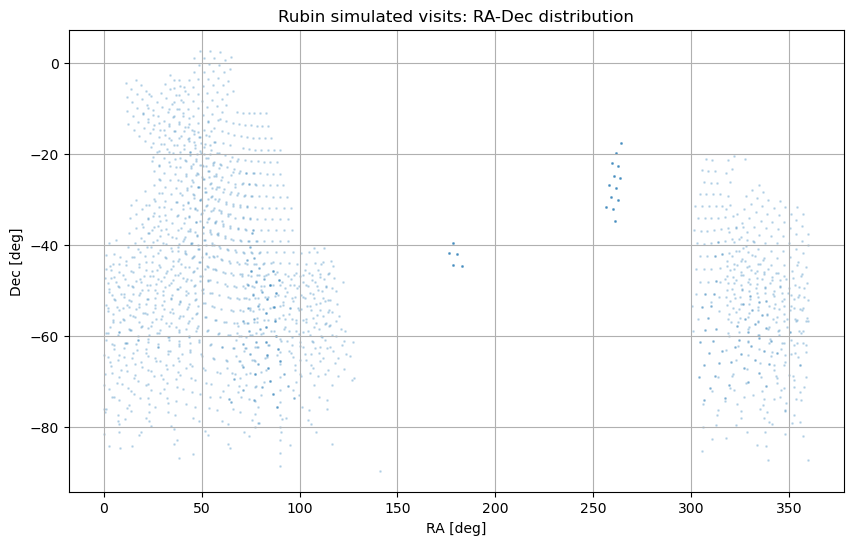

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    ra_dec_catalog["ra_deg"],
    ra_dec_catalog["dec_deg"],
    s=1,
    alpha=0.2,
)

plt.xlabel("RA [deg]")
plt.ylabel("Dec [deg]")

plt.title(
    "Rubin simulated visits: RA-Dec distribution"
)

plt.grid()

plt.show()


## Salvataggio finale

A questo punto nella directory:

```text
rubin_one_year_output/
```

dovresti avere:

```text
rubin_one_year.db
rubin_visits_ra_dec.csv
rubin_visits_ra_dec.parquet
```

Il DataFrame principale utilizzabile per le analisi successive è:

```python
ra_dec_catalog
```

Le colonne più importanti sono:

```text
mjd
datetime_utc
ra_deg
dec_deg
band
```

Il notebook può essere esteso per:

- selezionare regioni specifiche del cielo;
- studiare configurazioni del rotatore;
- trovare visite consecutive;
- calcolare tempi tra pointings;
- produrre mappe HEALPix;
- identificare automaticamente particolari configurazioni strumentali.
